<h2>Importowanie bibliotek oraz deklaracja stałych</h2>

In [10]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

label_mapping [
    'benign',
    'defacement',
    'phishing',
    'malware'
]

<h2>Inicjalizacja funkcji pomocniczych</h2>

In [13]:
def evaluate_model(prediction, Y_ground_truth):
    accuracy = accuracy_score(Y_ground_truth, prediction)
    f1 = f1_score(Y_ground_truth, prediction, average="macro")

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {f1:.4f}")

    # Classification Report
    report = classification_report(
        Y_ground_truth,
        prediction,
        target_names=label_mapping,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Pomijamy wiersze podsumowujące
    class_labels = [
        label for label in report_df.index
        if label not in ["accuracy", "macro avg", "weighted avg"]
    ]

    plt.figure(figsize=(9, 4))

    sns.heatmap(
        report_df.loc[
            class_labels,
            ["precision", "recall", "f1-score"]
        ],
        annot=True,
        fmt=".4f",
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    plt.title("Classification Report")
    plt.xlabel("Metric")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    labels = sorted(set(Y_ground_truth) | set(prediction))

    cm = confusion_matrix(
        Y_ground_truth,
        prediction,
        labels=labels
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_mapping,
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

<h2>Załadowanie dataseta zawierającego cechy</h2>

In [4]:
df = pd.read_csv("./../data/urls_features.csv")

print("Liczba rekordów:", df.shape[0])
print("Liczba kolumn:", df.shape[1])

print("\nInformacje o kolumnach:")
df.info()

Liczba rekordów: 641013
Liczba kolumn: 33

Informacje o kolumnach:
<class 'pandas.DataFrame'>
RangeIndex: 641013 entries, 0 to 641012
Data columns (total 33 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   url                       641013 non-null  str    
 1   type                      641013 non-null  str    
 2   domain                    628882 non-null  str    
 3   tld                       628881 non-null  str    
 4   suffix                    628881 non-null  str    
 5   subdomain                 250634 non-null  str    
 6   url_length                641013 non-null  int64  
 7   domain_length             641013 non-null  int64  
 8   subdomain_length          641013 non-null  int64  
 9   suffix_length             641013 non-null  int64  
 10  host_length               641013 non-null  int64  
 11  path_length               641013 non-null  int64  
 12  arguments_url_ratio       641013 non-null  f

<h2>Wykonanie podziału zbioru na podzbiory treningowe, walidacyjne i testowe w stosunku 70/15/15</h2>

In [2]:
from src.split_dataset import main
main()

Train:      448709 (70.00%)
Validation: 96152 (15.00%)
Test:       96152 (15.00%)


<h2>Załadowanie podzbiorów oraz weryfikacja odpowiedniego rozkładu poszczególnych klas</h2>

In [2]:
df_train = pd.read_csv("./../data/train.csv")
df_val = pd.read_csv("./../data/validation.csv")
df_test = pd.read_csv("./../data/test.csv")

class_counts = pd.DataFrame({
    "Original": df["type"].value_counts(),
    "Train": df_train["type"].value_counts(),
    "Validation": df_val["type"].value_counts(),
    "Test": df_test["type"].value_counts()
})

display(class_counts)

class_distribution = pd.DataFrame({
    "Original": df["type"].value_counts(normalize=True),
    "Train": df_train["type"].value_counts(normalize=True),
    "Validation": df_val["type"].value_counts(normalize=True),
    "Test": df_test["type"].value_counts(normalize=True)
}) * 100

display(class_distribution.round(2))

,Original,Train,Validation,Test
type,,,,
benign,428181,299727,64227,64227
defacement,95308,66716,14296,14296
phishing,93879,65715,14082,14082
malware,23645,16551,3547,3547


,Original,Train,Validation,Test
type,,,,
benign,66.80,66.80,66.80,66.80
defacement,14.87,14.87,14.87,14.87
phishing,14.65,14.65,14.65,14.65
malware,3.69,3.69,3.69,3.69


<h2>Wydobycie macierzy cech oraz etykiet z podzbiorów</h2>
Do macierzy cech nie trafiają kolumny zawierajće wartości tekstowe oraz etykiety

In [3]:
def get_features(df):
    return df[[c for c in df.columns if c not in ['url','type','domain','tld','suffix','subdomain','label']]]

#Utworzenie macierzy cech
X_train = get_features(df_train)
X_val = get_features(df_val)
X_test = get_features(df_test)

#Wydobycie etykiet
Y_train=df_train['label']
Y_val=df_val['label']
Y_test=df_test['label']



<h2>Wytrenowanie i ewaluacja modelu Random Forest stanowiącego baseline</h2>

Accuracy: 0.9664
Macro-F1: 0.9485


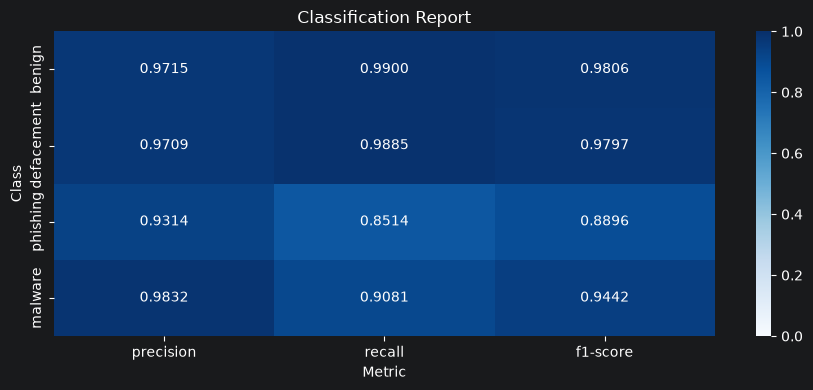

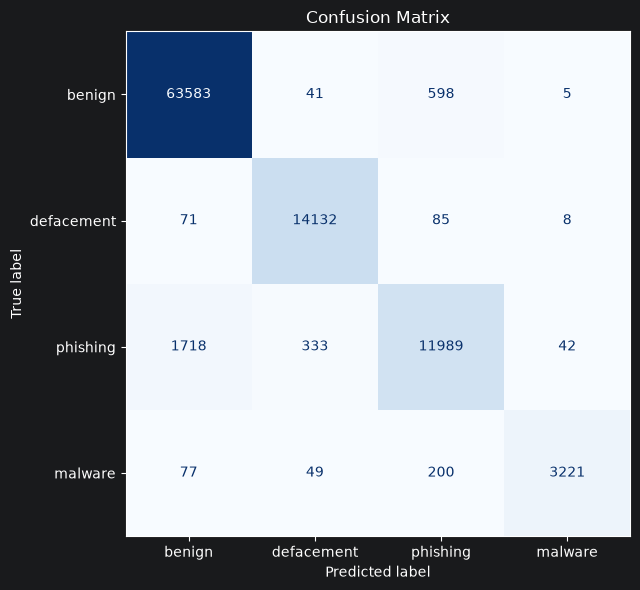

In [14]:
default_random_forest_model=RandomForestClassifier(random_state=42, n_jobs=-1)
default_random_forest_model.fit(X_train, Y_train)
predictions=default_random_forest_model.predict(X_val)
evaluate_model(predictions, Y_val)